# WAY-EEG-GAL: muscle onset before contact, detector state during the movement, and grip force forecast

Fourth stage. `putemg_force.ipynb` tested press detection and force forecasting with presses made from rest on a dynamometer. Here the pinch is part of a natural movement: the hand reaches for an object, grips it between thumb and index finger, lifts it, holds it, puts it back and returns to rest. This allows three questions that the earlier datasets could not address: when the arm and hand muscles become active relative to finger contact, whether a pinch detector stays quiet during the reach and the return, and whether the sEMG forecasts grip force when the object's weight changes without warning.

**Data.** WAY-EEG-GAL (Luciw, Jarocka and Edin 2014, *Scientific Data* 1:140047; figshare, CC BY 4.0): 12 participants, 9 series each with sEMG and force, 3,528 grasp-and-lift trials. Each trial starts with an LED cue; the participant reaches for the object, grasps it with the thumb and index finger, lifts it, holds it for a few seconds, puts it back, releases it and returns the hand to rest. The weight (165, 330 or 660 g) and the contact surface (sandpaper, suede or silk) change between trials without warning. sEMG of five muscles (anterior deltoid, brachioradialis, flexor digitorum, common extensor digitorum, first dorsal interosseous) at 4 kHz; force and torque of the index and thumb contact plates at 500 Hz; 16 event times per trial from the authors (for example hand start, first digit contact, lift-off). Download the 12 participant files with `python download_way_eeg_gal.py` (10.3 GB) or set `WAY_EEG_GAL` to the folder that holds `P1.zip` to `P12.zip`.

1. **Muscle onset (Figure 13).** When each muscle becomes active relative to the cue, the start of the hand movement and the first finger contact.
2. **Detector state during the movement (Figure 14).** The press detector of `putemg_force.ipynb`, applied to the two finger muscles (flexor digitorum and first dorsal interosseous): when it is on during each phase of the movement, and when it first fires in each trial.
3. **Grip force forecast (Figure 15).** The delay of best prediction and the forecast gain against repeating the model's own estimate (as Figures 9 and 11), split by whether the weight was the same as in the previous trial, heavier or lighter.

Features are causal, as in the earlier notebooks. Results for each person are cached in `results/way/`, so the notebook only processes new participants when it is run again.

In [1]:
import os, io, re, json, glob, zipfile, warnings
from pathlib import Path
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from scipy.signal import butter, iirnotch, tf2sos, sosfilt
from scipy.stats import wilcoxon
from IPython.display import Image, display
warnings.filterwarnings("ignore")
%matplotlib inline

REPO_DIR = Path.cwd()  # run the notebook from the repository folder
WAY_EEG_GAL = os.environ.get("WAY_EEG_GAL", "data/way_eeg_gal")
FIG_DIR, RES_DIR = REPO_DIR / "figures", REPO_DIR / "results"
CACHE_DIR = RES_DIR / "way"
for d in (FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
FS_EMG, FS_KIN = 4000, 500                # Hz, as recorded
FS_F, FS_D = 100, 1000                    # Hz: features and force for the models; detector and onsets
MUSCLES = ["anterior deltoid", "brachioradialis", "flexor digitorum", "extensor digitorum", "first dorsal interosseous"]
SHORT = ["AD", "BR", "FD", "ED", "FDI"]
HAND = [2, 4]                             # flexor digitorum and first dorsal interosseous: the detector's muscles
START, HMAX = 100, 20                     # skip the first 1 s of a series; keep 200 ms at the end for future targets
HORIZONS_MS = [30, 50, 70, 100, 150, 200]
DELAYS_MS = list(range(-100, 310, 10))
LAGS = (0, 3, 6)
ALPHAS = [1.0, 10.0, 100.0, 1000.0]
WIN_MS, DET_WIN_MS = 50, 20
PHASES = ["rising", "steady", "falling"]
WEIGHT_CASES = ["same", "heavier", "lighter"]
MODELS = ["EMG forecast", "baseline 1: own estimate", "baseline 2: measured force"]
REST_AFTER_STOP = 0.3                     # s after the hand stops before the hand counts as at rest
ONSET_K, ONSET_MS = 3, 25                 # onset: z above 3 for 25 ms
DET_K = (3, 5, 8)                         # detector threshold: rest mean + k SD
DET_CONF_MS = (10, 25, 50)                # confirmation time
DET_REARM_MS = 200                        # the detector fires again only after this long below threshold
BEFORE_CONTACT_MS = 200
DET_PHASES = ["hand at rest", "reach", "last 200 ms before contact", "grip, lift and hold", "release and return"]
FIRST_FIRE = ["already on", "hand at rest", "reach", "last 200 ms before contact", "after contact", "no firing"]
ALIGN = (-1.5, 1.0)                       # s around first contact for the average time courses
N_BOOT, BLOCK = 500, 100
SEED = 7
CACHE_VERSION = 1
WEIGHT_G = {1: 165, 2: 330, 4: 660}       # weight codes in the trial table

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=900))
    print("saved", path.relative_to(REPO_DIR))


setup()

## Reading and features

Each participant file holds, per series, the continuous recording (`HS_P*_S*.mat`) and a table of all trials (`P*_AllLifts.mat`) whose event times are given relative to a window that starts 2 s before the cue. Grip force is the mean of the normal forces on the index and thumb plates. In the series where the contact surfaces were changed, the plates also record the experimenter handling the object between trials, so grip force is set to zero outside the period from 0.1 s before first contact to 0.2 s after release. The sEMG is band-pass filtered (20–450 Hz) with notches at the 50 Hz mains harmonics, all causal, and summarised per muscle as the log RMS over a trailing window: 50 ms every 10 ms for the models, 20 ms every 1 ms for the onsets and the detector.

In [3]:
def participants():
    return sorted(int(Path(f).stem[1:]) for f in glob.glob(os.path.join(WAY_EEG_GAL, "P*.zip")))


def _load(z, name):
    return sio.loadmat(io.BytesIO(z.read(name)), squeeze_me=True, struct_as_record=False)


def trial_table(z, p):
    P = _load(z, f"P{p}_AllLifts.mat")["P"]
    return P.AllLifts, {str(c): i for i, c in enumerate(P.ColNames)}


def read_series(z, p, s):
    """sEMG (n x 5, 4 kHz) and grip force (500 Hz, N) of one continuous series."""
    hs = _load(z, f"HS_P{p}_S{s}.mat")["hs"]
    assert [str(m) for m in hs.emg.names][:3] == ["Anterior Deltoid", "Brachoradial", "Flexor Digitorum"]
    kin, names = hs.kin.sig, [str(m) for m in hs.kin.names]
    gf = -(kin[:, names.index("FZ1 - force z plate 1")] + kin[:, names.index("FZ2 - force z plate 2")]) / 2
    return np.asarray(hs.emg.sig, np.float64), np.asarray(gf, np.float64)


def trials(A, C, s):
    """Event times of the trials of series s, in seconds from the start of the continuous recording."""
    rows = A[A[:, C["Run"]] == s]
    rows = rows[np.argsort(rows[:, C["Lift"]])]
    off = rows[:, C["StartTime"]] - 2.0
    ev = lambda col: rows[:, C[col]] + off
    T = dict(cue=ev("LEDOn"), hand_start=ev("tHandStart"), contact=ev("tFirstDigitTouch"), lift_off=ev("tLiftOff"),
             replace=ev("tReplace"), released=ev("tBothReleased"), hand_stop=ev("tHandStop"))
    T["weight"], T["prev_weight"] = rows[:, C["CurW"]], rows[:, C["PrevW"]]
    return T


def emg_sos(fs):
    """Causal band-pass 20-450 Hz and notches at the 50 Hz mains harmonics."""
    sos = butter(4, [20, 450], btype="band", fs=fs, output="sos")
    for k in range(50, 451, 50):
        b, a = iirnotch(k, 30, fs)
        sos = np.vstack([sos, tf2sos(b, a)])
    return sos


def trailing_log_rms(c, idx, w):
    lo = np.clip(idx - w, 0, None)
    return np.log(np.sqrt(np.maximum(c[idx] - c[lo], 0) / np.maximum(idx - lo, 1)[:, None]) + 1e-6)


def features(emg, gf):
    """Per-muscle causal features at 100 Hz (L) and 1 kHz (D): the value at time tau uses sEMG samples up to tau only.
    Grip force at 100 Hz (F) is taken at the same times."""
    n = len(emg)
    x = sosfilt(emg_sos(FS_EMG), emg, axis=0)
    c = np.vstack([np.zeros((1, emg.shape[1])), np.cumsum(x ** 2, 0)])
    R = {}
    for r, w, key in ((FS_F, WIN_MS, "L"), (FS_D, DET_WIN_MS, "D")):
        idx = np.clip(np.floor(np.arange(int(np.floor((n - 1) / FS_EMG * r))) / r * FS_EMG).astype(int) + 1, 1, n)
        R[key] = trailing_log_rms(c, idx, int(round(w / 1000 * FS_EMG))).astype(np.float32)
    R["F"] = gf[np.clip(np.arange(len(R["L"])) * (FS_KIN // FS_F) - 1, 0, len(gf) - 1)]
    return R


def load(z, p, s, A, C):
    R = features(*read_series(z, p, s))
    R["T"] = T = trials(A, C, s)
    t = np.arange(len(R["F"])) / FS_F
    inside = np.zeros(len(t), bool)
    for a, b in zip(T["contact"] - 0.1, T["released"] + 0.2):
        inside |= (t >= a) & (t < b)
    R["F"] = np.where(inside, R["F"], 0.0)
    return R

## Check: the features do not look ahead

At three random times the sEMG after *t* is set to zero and the features are recomputed. A causal feature at *t* must not change.

In [4]:
SUBJECTS = participants()
print(f"{len(SUBJECTS)} participants found")
assert SUBJECTS, "no WAY-EEG-GAL files found: run download_way_eeg_gal.py or set WAY_EEG_GAL"

with zipfile.ZipFile(os.path.join(WAY_EEG_GAL, f"P{SUBJECTS[0]}.zip")) as z_:
    emg_, gf_ = read_series(z_, SUBJECTS[0], 1)
full = features(emg_, gf_)
LOOKAHEAD = dict(model_features=0.0, detector_features=0.0)
for k in np.random.default_rng(SEED).integers(500, len(full["L"]) - 500, 3):
    cut = int(np.floor(k / FS_F * FS_EMG)) + 1          # sEMG samples available at feature sample k
    e2 = emg_.copy()
    e2[cut:] = 0
    part = features(e2, gf_)
    LOOKAHEAD["model_features"] = max(LOOKAHEAD["model_features"], float(np.abs(part["L"][k] - full["L"][k]).max()))
    kd = k * FS_D // FS_F
    LOOKAHEAD["detector_features"] = max(LOOKAHEAD["detector_features"], float(np.abs(part["D"][kd] - full["D"][kd]).max()))
for k, v in LOOKAHEAD.items():
    print(f"{k:18s} largest change when the future is removed: {v:.1e} (log units)")
assert max(LOOKAHEAD.values()) < 1e-6
del emg_, gf_, full, part, e2

12 participants found
model_features     largest change when the future is removed: 0.0e+00 (log units)
detector_features  largest change when the future is removed: 0.0e+00 (log units)


## Phases of the movement

From the authors' event times. **Hand at rest:** from 0.3 s after the hand stopped (or 1 s into the series) to the start of the next hand movement; the part before the cue is the rest reference. **Reach:** hand start to 200 ms before the first finger contact. **Last 200 ms before contact.** **Grip, lift and hold:** first contact to the moment the object is put back. **Release and return:** from then until 0.3 s after the hand stops.

In [5]:
def phase_codes(T, n, rate):
    """Phase index (DET_PHASES) at each sample, -1 where undefined, and the rest-reference mask."""
    ph = np.full(n, -1, np.int8)
    ref = np.zeros(n, bool)
    i = lambda t: int(np.clip(round(t * rate), 0, n))
    prev = 1.0
    for j in range(len(T["cue"])):
        bounds = [prev, T["hand_start"][j], T["contact"][j] - BEFORE_CONTACT_MS / 1000, T["contact"][j], T["replace"][j],
                  T["hand_stop"][j] + REST_AFTER_STOP]
        for k in range(5):
            if bounds[k + 1] > bounds[k]:
                ph[i(bounds[k]):i(bounds[k + 1])] = k
        if T["cue"][j] - 0.05 > prev:
            ref[i(prev):i(T["cue"][j] - 0.05)] = True
        prev = bounds[-1]
    ph[i(prev):] = 0
    ref[i(prev):i(n / rate - 0.2)] = True
    return ph, ref


def lift_labels(T, n, rate):
    """Trial index and weight case (0 same, 1 heavier, 2 lighter than the previous trial) from first contact to put-down."""
    lift, case = np.full(n, -1, np.int16), np.full(n, -1, np.int8)
    for j in range(len(T["cue"])):
        a, b = int(round(T["contact"][j] * rate)), int(round(T["replace"][j] * rate))
        lift[a:b] = j
        w, pw = T["weight"][j], T["prev_weight"][j]
        if not np.isnan(pw):
            case[a:b] = 0 if w == pw else (1 if w > pw else 2)
    return lift, case

## Analysis for one person

**Onsets.** In each trial, each muscle's 20 ms log RMS is z-scored against the hand at rest just before the cue (up to 1 s, at least 0.3 s). The onset is the first time after the cue at which z stays above 3 for 25 ms, searched up to 300 ms after first contact; an onset in the first 50 ms after the cue is not used, because it cannot be a response to the cue. Times are given relative to first contact and to the start of the hand movement. The average time courses are the median over trials of the log RMS relative to that rest level, aligned to first contact.

**Detector.** As in `putemg_force.ipynb`, with the flexor digitorum and the first dorsal interosseous: each muscle's 20 ms log RMS is z-scored against the hand at rest in series 1, and the detector follows the mean of the two. It fires when that value stays above *k* for a confirmation time and fires again only after 200 ms below *k*; it is on from a firing until the value falls below *k* for 200 ms. Test: series 2 to 9. For each trial, the first firing between rest and put-down is placed in a phase; "already on" means the detector was still on when the hand came to rest after the previous trial.

**Grip force forecast.** As in the earlier notebooks, with the five muscles: z-scoring, lags of 0, 30 and 60 ms and ridge regression with the penalty chosen by blocked cross-validation inside the calibration data. Each series is tested with a model calibrated on the other eight. Phases (rising, steady, falling force) come from the measured force, for evaluation only. Gain = error of baseline 1 minus error of the sEMG forecast, in points of a typical grip (95th percentile of grip force), with a moving-block bootstrap interval within the person (1 s blocks). The weight cases use the samples between first contact and put-down, with the force rising, split by the weight relative to the previous trial.

In [6]:
H_ALL = [0] + [hm // 10 for hm in HORIZONS_MS]


def shift(Z, L):
    out = np.zeros_like(Z)
    if L == 0:
        return Z.copy()
    out[L:] = Z[:-L]
    return out


def design(Z):
    return np.hstack([shift(Z, L) for L in LAGS])


def eval_idx(n, end=HMAX):
    return np.arange(START, n - end)


def _stats(X, Y):
    return [X.T @ X, X.sum(0), X.T @ Y, Y.sum(0), len(X)]


def _solve(st, a):
    G, xs, XY, ys, n = st
    mx, my = xs / n, ys / n
    W = np.linalg.solve(G - n * np.outer(mx, mx) + a * np.eye(len(mx)), XY - n * np.outer(mx, my))
    return W, my - mx @ W


def ridge(X, y, idx, shifts, gap):
    """Ridge with intercept predicting y[t + d] for each d in `shifts` from X[t], t in idx. The penalty of each target
    is chosen by blocked cross-validation (5 blocks; `gap` samples around the validation block are left out)."""
    Xi = X[idx]
    Y = np.stack([y[idx + d] for d in shifts], 1)
    tot = _stats(Xi, Y)
    sse = np.zeros((len(ALPHAS), len(shifts)))
    for b in np.array_split(np.arange(len(idx)), 5):
        out = (idx >= idx[b[0]] - gap) & (idx <= idx[b[-1]] + gap)
        tr = [u - v for u, v in zip(tot, _stats(Xi[out], Y[out]))]
        for i, a in enumerate(ALPHAS):
            W, c = _solve(tr, a)
            sse[i] += ((Xi[b] @ W + c - Y[b]) ** 2).sum(0)
    best = np.argmin(sse, 0)
    W, c = np.zeros((X.shape[1], len(shifts))), np.zeros(len(shifts))
    for i in set(best.tolist()):
        Wi, ci = _solve(tot, ALPHAS[i])
        W[:, best == i], c[best == i] = Wi[:, best == i], ci[best == i]
    return W, c


def calib(recs, end):
    """Concatenate recordings: z-scored design matrix inputs, force and the indices usable as calibration samples."""
    L, F, idx, off = [], [], [], 0
    for r in recs:
        L.append(r["L"]); F.append(r["F"]); idx.append(eval_idx(len(r["L"]), end) + off); off += len(r["L"])
    return np.vstack(L), np.concatenate(F), np.concatenate(idx)


def zscore_fit(L, idx):
    return L[idx].mean(0), L[idx].std(0) + 1e-9


def r2(p, y):
    return float(1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2))


PH_CODE = {"rest": 0, "rising": 1, "steady": 2, "falling": 3}


def phase_labels(y, rest, ref):
    """Evaluation only: rising / falling / steady / rest from the measured force (centred smoothing)."""
    a = np.abs(y - rest)
    sm = np.convolve(a, np.ones(5) / 5, mode="same")
    d = np.zeros_like(sm)
    d[5:-5] = sm[10:] - sm[:-10]
    thr, near = 0.15 * ref, 0.10 * ref
    lab = np.full(len(y), PH_CODE["steady"], np.int8)
    lab[d > thr] = PH_CODE["rising"]
    lab[d < -thr] = PH_CODE["falling"]
    lab[(np.abs(d) <= thr) & (sm <= near)] = PH_CODE["rest"]
    return lab


def rest_force(r):
    ph, ref = phase_codes(r["T"], len(r["F"]), FS_F)
    return float(np.median(r["F"][ref]))


def onsets(r):
    """Onset of each muscle in each trial (s, relative to first contact; NaN if none) and time courses aligned to contact."""
    T, D = r["T"], r["D"]
    n = len(D)
    i = lambda t: int(round(t * FS_D))
    a0, a1 = int(round(ALIGN[0] * FS_D)), int(round(ALIGN[1] * FS_D))
    out, curves, ok = [], [], []
    prev = 1.0
    for j in range(len(T["cue"])):
        cue, con = T["cue"][j], T["contact"][j]
        b0, b1 = max(prev, cue - 1.0), cue - 0.05
        prev = T["hand_stop"][j] + REST_AFTER_STOP
        if b1 - b0 < 0.3 or i(con) + a1 > n or i(con) + a0 < 0:
            out.append([np.nan] * 5); ok.append(False)
            continue
        base = D[i(b0):i(b1)].astype(np.float64)
        mu, sd = base.mean(0), base.std(0) + 1e-9
        z = (D[i(cue):i(con + 0.3)] - mu) / sd
        o = []
        for m in range(5):
            run = np.convolve((z[:, m] > ONSET_K).astype(np.int16), np.ones(ONSET_MS, np.int16), "valid") >= ONSET_MS
            k = int(np.argmax(run)) if run.any() else -1
            o.append(cue + k / FS_D - con if k >= 50 else np.nan)
        out.append(o); ok.append(True)
        curves.append(D[i(con) + a0:i(con) + a1:10] - mu)
    return np.array(out), np.array(ok), curves


def det_stat(D, mu, sd):
    return ((D[:, HAND] - mu[HAND]) / sd[HAND]).mean(1)


def fire_state(stat, k, conf):
    """Firing times and on-state of the detector."""
    above = np.r_[False, stat > k, False]
    d = np.diff(above.astype(np.int8))
    st, en = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    fires, on, i = [], np.zeros(len(stat), bool), 0
    while i < len(st):
        j = i
        while j + 1 < len(st) and st[j + 1] - en[j] < DET_REARM_MS:
            j += 1
        for q in range(i, j + 1):
            if en[q] - st[q] >= conf:
                f = st[q] + conf - 1
                fires.append(f)
                on[f:en[j]] = True
                break
        i = j + 1
    return np.array(fires, int), on


def detection(cal, tests):
    ph_c, ref_c = phase_codes(cal["T"], len(cal["D"]), FS_D)
    mu, sd = cal["D"][ref_c].mean(0), cal["D"][ref_c].std(0) + 1e-6
    out = {}
    for k in DET_K:
        for conf in DET_CONF_MS:
            o = dict(on_s={p: 0.0 for p in DET_PHASES}, phase_s={p: 0.0 for p in DET_PHASES}, first={c: 0 for c in FIRST_FIRE},
                     first_ms=[], rest_fires=0)
            for r in tests:
                st = det_stat(r["D"], mu, sd)
                fires, on = fire_state(st, k, conf)
                ph, _ = phase_codes(r["T"], len(st), FS_D)
                for q, p in enumerate(DET_PHASES):
                    o["phase_s"][p] += float((ph == q).sum()) / FS_D
                    o["on_s"][p] += float((on & (ph == q)).sum()) / FS_D
                o["rest_fires"] += int((ph[fires] == 0).sum())
                T, prev = r["T"], 1.0
                for j in range(len(T["cue"])):
                    a, b = int(round(prev * FS_D)), int(round(T["replace"][j] * FS_D))
                    prev = T["hand_stop"][j] + REST_AFTER_STOP
                    if b <= a:
                        continue
                    f = fires[(fires >= a) & (fires < b)]
                    if on[a]:
                        cat = "already on"
                    elif not len(f):
                        cat = "no firing"
                    else:
                        t = f[0] / FS_D
                        o["first_ms"].append(int(round((t - T["contact"][j]) * 1000)))
                        cat = ("hand at rest" if t < T["hand_start"][j] else "reach" if t < T["contact"][j] - BEFORE_CONTACT_MS / 1000
                               else "last 200 ms before contact" if t < T["contact"][j] else "after contact")
                    o["first"][cat] += 1
            out[f"k{k}_c{conf}"] = dict(
                on_fraction={p: round(o["on_s"][p] / o["phase_s"][p], 3) if o["phase_s"][p] else None for p in DET_PHASES},
                first_firing={c: o["first"][c] for c in FIRST_FIRE},
                first_firing_ms_median=float(np.median(o["first_ms"])) if o["first_ms"] else None,
                rest_false_alarms_per_min=round(o["rest_fires"] / (o["phase_s"]["hand at rest"] / 60), 2),
                minutes={p: round(o["phase_s"][p] / 60, 2) for p in DET_PHASES})
    return out


def delay_and_forecast(REC):
    """Leave one series out: delay profile (R2 by delay), squared forecast errors and labels, test series joined."""
    shifts = [d // 10 for d in DELAYS_MS]
    hi = max(shifts)
    prof_num, prof_den = np.zeros(len(shifts)), np.zeros(len(shifts))
    E = {(nm, hm): [] for nm in MODELS for hm in HORIZONS_MS}
    LAB = {hm: [] for hm in HORIZONS_MS}
    CASE = {hm: [] for hm in HORIZONS_MS}
    r2_0 = []
    for q, test in enumerate(REC):
        cal = [r for k, r in enumerate(REC) if k != q]
        Lc, Fc, ic = calib(cal, hi)
        mu, sd = zscore_fit(Lc, ic)
        Xc, Xt = design((Lc - mu) / sd), design((test["L"] - mu) / sd)
        it = eval_idx(len(test["L"]), hi)
        W, c = ridge(Xc, Fc, ic, shifts, 50 + hi)
        P = Xt[it] @ W + c
        Y = np.stack([test["F"][it + d] for d in shifts], 1)
        prof_num += ((P - Y) ** 2).sum(0); prof_den += ((Y - Y.mean(0)) ** 2).sum(0)
        Lc, Fc, ic = calib(cal, HMAX)
        mu, sd = zscore_fit(Lc, ic)
        Xc, Xt = design((Lc - mu) / sd), design((test["L"] - mu) / sd)
        it = eval_idx(len(test["L"]))
        W, c = ridge(Xc, Fc, ic, H_ALL, 50 + HMAX)
        P = Xt @ W + c
        yt = test["F"]
        r2_0.append((float(((P[it, 0] - yt[it]) ** 2).sum()), float(((yt[it] - yt[it].mean()) ** 2).sum())))
        rest_c = float(np.median([rest_force(r) for r in cal]))
        ref = np.percentile(np.abs(Fc[ic] - rest_c), 95)
        rest_t = rest_force(test)
        scale = np.percentile(np.abs(yt[it] - rest_t), 95)
        ph = phase_labels(yt, rest_t, ref)
        _, case = lift_labels(test["T"], len(yt), FS_F)
        for k, hm in enumerate(HORIZONS_MS):
            h = hm // 10
            LAB[hm].append(ph[it + h]); CASE[hm].append(case[it + h])
            for nm, v in zip(MODELS, [P[:, k + 1], P[:, 0], yt]):
                E[(nm, hm)].append(((v[it] - yt[it + h]) / scale) ** 2)
    prof = 1 - prof_num / prof_den
    r2_h0 = 1 - sum(a for a, b in r2_0) / sum(b for a, b in r2_0)
    return prof, r2_h0, {k: np.concatenate(v) for k, v in E.items()}, {k: np.concatenate(v) for k, v in LAB.items()}, \
        {k: np.concatenate(v) for k, v in CASE.items()}


def gains(E, masks, rng):
    """Gain of the sEMG forecast over baselines 1 and 2 for each mask, with a moving-block bootstrap interval."""
    N = len(E[(MODELS[0], HORIZONS_MS[0])])
    starts = rng.integers(0, N, (N_BOOT, N // BLOCK))

    def rmse(nm, hm, m):
        e = E[(nm, hm)]
        v, c = np.where(m, e, 0), m.astype(np.float64)
        cv, cc = np.r_[0, np.cumsum(np.r_[v, v[:BLOCK]])], np.r_[0, np.cumsum(np.r_[c, c[:BLOCK]])]
        bv, bc = (cv[starts + BLOCK] - cv[starts]).sum(1), (cc[starts + BLOCK] - cc[starts]).sum(1)
        return 100 * np.sqrt(v.sum() / max(c.sum(), 1)), 100 * np.sqrt(bv / np.maximum(bc, 1))

    out = {}
    for b in MODELS[1:]:
        out[b] = {}
        for name, mk in masks.items():
            est, lo, hi, n = [], [], [], []
            for hm in HORIZONS_MS:
                m = mk(hm)
                (eb, bb), (ef, bf) = rmse(b, hm, m), rmse(MODELS[0], hm, m)
                est.append(round(float(eb - ef), 2))
                lo.append(round(float(np.percentile(bb - bf, 2.5)), 2)); hi.append(round(float(np.percentile(bb - bf, 97.5)), 2))
                n.append(int(m.sum()))
            out[b][name] = dict(gain=est, ci95=[[a, c] for a, c in zip(lo, hi)], samples=n)
    return out


def analyse(p):
    path = CACHE_DIR / f"participant{p:02d}.json"
    if path.exists():
        r = json.loads(path.read_text())
        if r.get("version") == CACHE_VERSION:
            return r
    with zipfile.ZipFile(os.path.join(WAY_EEG_GAL, f"P{p}.zip")) as z:
        A, C = trial_table(z, p)
        series = sorted(int(v) for v in np.unique(A[:, C["Run"]]))
        REC = [load(z, p, s, A, C) for s in series]
    res = dict(version=CACHE_VERSION, participant=p, series=len(REC), trials=int(sum(len(r["T"]["cue"]) for r in REC)))
    # onsets and time courses
    O, OK, curves, rel_start, t_ev = [], [], [], [], {k: [] for k in ("cue", "hand_start", "lift_off")}
    for r in REC:
        o, ok, cv = onsets(r)
        O.append(o); OK.append(ok); curves += cv
        rel_start.append(o + (r["T"]["contact"] - r["T"]["hand_start"])[:, None])
        for k in t_ev:
            t_ev[k].append(r["T"][k] - r["T"]["contact"])
    O, OK, rel_start = np.vstack(O), np.concatenate(OK), np.vstack(rel_start)
    res["onset_trials_used"] = int(OK.sum())
    res["onset_found"] = {SHORT[m]: round(float(np.isfinite(O[OK, m]).mean()), 3) for m in range(5)}
    res["onset_vs_contact_ms"] = {SHORT[m]: round(float(np.nanmedian(O[OK, m]) * 1000), 1) for m in range(5)}
    res["onset_vs_hand_start_ms"] = {SHORT[m]: round(float(np.nanmedian(rel_start[OK, m]) * 1000), 1) for m in range(5)}
    res["onset_before_contact"] = {SHORT[m]: round(float((O[OK, m] < 0).sum() / OK.sum()), 3) for m in range(5)}
    res["events_vs_contact_ms"] = {k: round(float(np.median(np.concatenate(v)) * 1000), 1) for k, v in t_ev.items()}
    res["curve_log_rms_vs_rest"] = np.round(np.median(np.array(curves), 0), 4).T.tolist()
    # grip force aligned to contact (for the figure)
    gfc = []
    for r in REC:
        for con in r["T"]["contact"]:
            a = int(round((con + ALIGN[0]) * FS_F))
            if a >= 0 and a + int(round((ALIGN[1] - ALIGN[0]) * FS_F)) < len(r["F"]):
                gfc.append(r["F"][a:a + int(round((ALIGN[1] - ALIGN[0]) * FS_F))])
    res["curve_grip_force_N"] = np.round(np.median(gfc, 0), 3).tolist()
    # detector
    res["detection"] = detection(REC[0], REC[1:])
    # delay profile and forecast
    prof, r2_h0, E, LAB, CASE = delay_and_forecast(REC)
    res["delay_profile_r2"] = [round(float(v), 4) for v in prof]
    res["r2_h0"] = round(float(r2_h0), 3)
    rng = np.random.default_rng(SEED + p)
    masks = {ph: (lambda hm, ph=ph: LAB[hm] == PH_CODE[ph]) for ph in PHASES}
    masks.update({f"rising, {c}": (lambda hm, q=q: (LAB[hm] == PH_CODE["rising"]) & (CASE[hm] == q)) for q, c in enumerate(WEIGHT_CASES)})
    res["gain_points"] = gains(E, masks, rng)
    path.write_text(json.dumps(res))
    return res

## Run all participants

In [7]:
RES = {}
for p in SUBJECTS:
    r = analyse(p)
    RES[p] = r
    d = r["detection"]["k5_c25"]
    g = r["gain_points"]["baseline 1: own estimate"]["rising"]["gain"][HORIZONS_MS.index(100)]
    print(f"participant {p:02d}: {r['trials']} trials | onset vs hand start: FD {r['onset_vs_hand_start_ms']['FD']:+.0f} ms, "
          f"FDI {r['onset_vs_hand_start_ms']['FDI']:+.0f} ms | detector (5 SD, 25 ms) on during reach {d['on_fraction']['reach']:.0%}, "
          f"during grip {d['on_fraction']['grip, lift and hold']:.0%} | best delay {DELAYS_MS[int(np.argmax(r['delay_profile_r2']))]} ms | "
          f"gain at 100 ms, force rising {g:+.1f}")
OK = sorted(RES)
print(f"\n{len(OK)} participants, {sum(RES[p]['trials'] for p in OK)} trials")

participant 01: 294 trials | onset vs hand start: FD -10 ms, FDI -29 ms | detector (5 SD, 25 ms) on during reach 0%, during grip 63% | best delay 120 ms | gain at 100 ms, force rising -1.3
participant 02: 294 trials | onset vs hand start: FD +552 ms, FDI +62 ms | detector (5 SD, 25 ms) on during reach 3%, during grip 86% | best delay 130 ms | gain at 100 ms, force rising -0.5
participant 03: 294 trials | onset vs hand start: FD +102 ms, FDI +117 ms | detector (5 SD, 25 ms) on during reach 2%, during grip 1% | best delay 150 ms | gain at 100 ms, force rising +0.1
participant 04: 294 trials | onset vs hand start: FD +54 ms, FDI -66 ms | detector (5 SD, 25 ms) on during reach 66%, during grip 59% | best delay 300 ms | gain at 100 ms, force rising +0.0
participant 05: 294 trials | onset vs hand start: FD +704 ms, FDI +195 ms | detector (5 SD, 25 ms) on during reach 0%, during grip 1% | best delay 80 ms | gain at 100 ms, force rising +0.3
participant 06: 294 trials | onset vs hand start: FD

## Figure 13 · Muscle onset relative to the movement and to finger contact

**a.** sEMG of each muscle relative to its level with the hand at rest before the cue, aligned to the first finger contact: median over trials for each person, then median across people (log scale). Vertical lines: median times of the cue, the start of the hand movement and lift-off. Below: grip force, median across people. AD anterior deltoid, BR brachioradialis, FD flexor digitorum, ED extensor digitorum, FDI first dorsal interosseous. **b.** Onset of each muscle relative to the start of the hand movement: one point per person (median over trials), black line at the median across people. Negative values are before the hand starts moving.

onset: median across people of each person's median [IQR] | people with onset after hand start | trials with an onset (median)
  anterior deltoid           vs contact  -1206 ms [-1394.0, -920.9] | vs hand start  -138 ms [-179.0, -114.8] | 0 of 12 | 99%
  brachioradialis            vs contact  -1164 ms [-1309.8, -858.2] | vs hand start  -104 ms [-139.1, -86.9] | 0 of 12 | 95%
  flexor digitorum           vs contact   -474 ms [-611.6, -321.2] | vs hand start  +610 ms [90.0, 916.1] | 11 of 12 | 75%
  extensor digitorum         vs contact  -1117 ms [-1210.5, -795.2] | vs hand start   -62 ms [-80.0, 101.0] | 4 of 12 | 99%
  first dorsal interosseous  vs contact   -820 ms [-911.8, -738.8] | vs hand start   +82 ms [33.1, 221.0] | 10 of 12 | 100%
first dorsal interosseous, halfway to its peak after contact: median 105 ms [97.5, 162.5]; grip force: 225 ms [195.0, 270.0]; sEMG first in 11 of 12
event times relative to first contact (median across people [IQR]): cue -1469 ms [-1710.5, -1145.5]; h

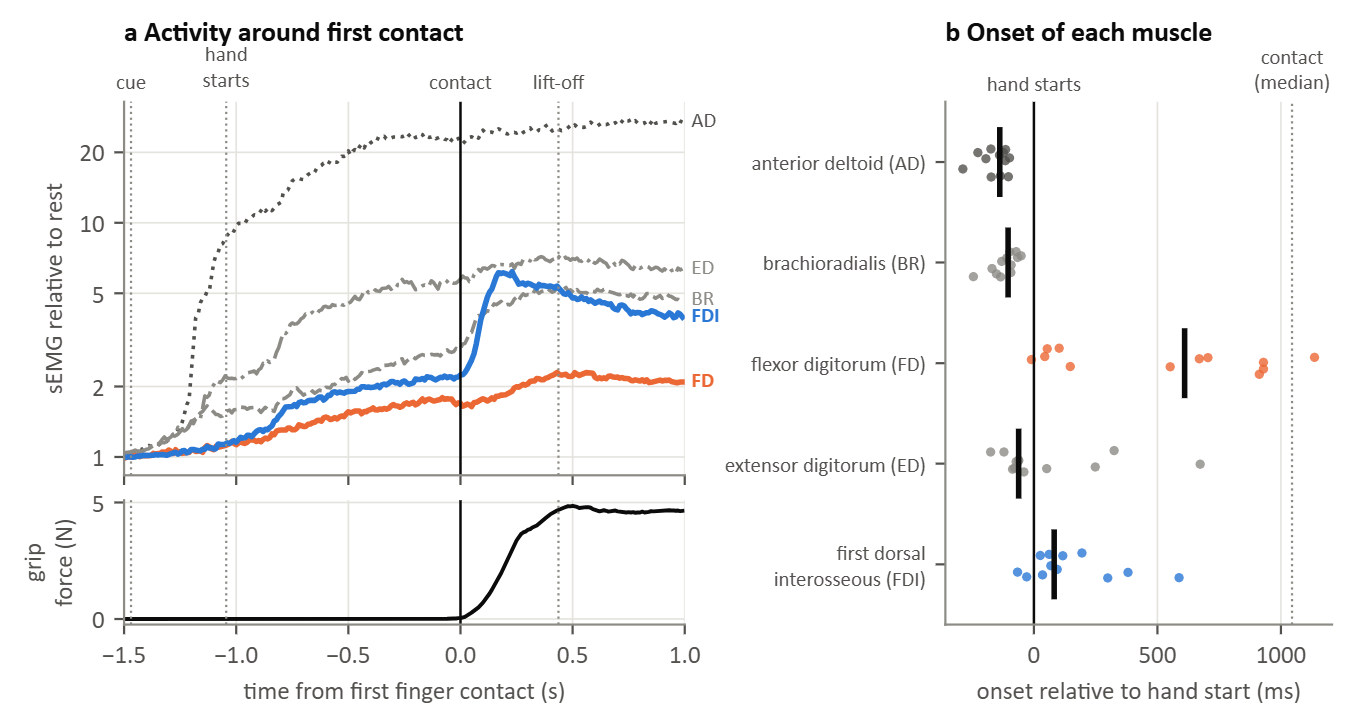

saved figures/figure13.png


In [8]:
TT = np.arange(int(round(ALIGN[0] * 100)), int(round(ALIGN[1] * 100))) / 100     # s from first contact, every 10 ms
CUR = np.array([RES[p]["curve_log_rms_vs_rest"] for p in OK])                     # people x muscles x time (log units)
GFC = np.array([RES[p]["curve_grip_force_N"] for p in OK])
EVP = {k: np.array([RES[p]["events_vs_contact_ms"][k] for p in OK]) for k in ("cue", "hand_start", "lift_off")}
EV = {k: float(np.median(v)) / 1000 for k, v in EVP.items()}
ON_C = np.array([[RES[p]["onset_vs_contact_ms"][m] for m in SHORT] for p in OK])
ON_H = np.array([[RES[p]["onset_vs_hand_start_ms"][m] for m in SHORT] for p in OK])
FOUND = np.array([[RES[p]["onset_found"][m] for m in SHORT] for p in OK])
q = lambda v: [round(float(np.percentile(v, 25)), 1), round(float(np.percentile(v, 75)), 1)]
ONSETS = {}
print("onset: median across people of each person's median [IQR] | people with onset after hand start | trials with an onset (median)")
for k, m in enumerate(SHORT):
    ONSETS[m] = dict(vs_contact_ms=dict(median=float(np.median(ON_C[:, k])), iqr=q(ON_C[:, k])),
                     vs_hand_start_ms=dict(median=float(np.median(ON_H[:, k])), iqr=q(ON_H[:, k])),
                     people_after_hand_start=int(np.sum(ON_H[:, k] > 0)), trials_with_onset_median=float(np.median(FOUND[:, k])))
    o = ONSETS[m]
    print(f"  {MUSCLES[k]:26s} vs contact {o['vs_contact_ms']['median']:+6.0f} ms {o['vs_contact_ms']['iqr']} | "
          f"vs hand start {o['vs_hand_start_ms']['median']:+5.0f} ms {o['vs_hand_start_ms']['iqr']} | "
          f"{o['people_after_hand_start']} of {len(OK)} | {o['trials_with_onset_median']:.0%}")
i0 = -int(round(ALIGN[0] * 100))


def half_time(v):
    """Time after contact (ms) at which v first reaches halfway between its value at contact and its peak in the next 600 ms."""
    base, pk = v[i0], v[i0:i0 + 60].max()
    return float(TT[i0 + np.argmax(v[i0:] >= base + 0.5 * (pk - base))] * 1000)


FDI_HALF = np.array([half_time(np.exp(c[SHORT.index("FDI")])) for c in CUR])
GF_HALF = np.array([half_time(g) for g in GFC])
BURST = dict(fdi_half_rise_after_contact_ms=dict(median=float(np.median(FDI_HALF)), iqr=q(FDI_HALF)),
             grip_force_half_rise_after_contact_ms=dict(median=float(np.median(GF_HALF)), iqr=q(GF_HALF)),
             people_fdi_before_grip_force=int(np.sum(FDI_HALF < GF_HALF)))
print(f"first dorsal interosseous, halfway to its peak after contact: median {BURST['fdi_half_rise_after_contact_ms']['median']:.0f} ms "
      f"{BURST['fdi_half_rise_after_contact_ms']['iqr']}; grip force: {BURST['grip_force_half_rise_after_contact_ms']['median']:.0f} ms "
      f"{BURST['grip_force_half_rise_after_contact_ms']['iqr']}; sEMG first in {BURST['people_fdi_before_grip_force']} of {len(OK)}")
EVENTS = {k: dict(median_ms=float(np.median(v)), iqr_ms=q(v)) for k, v in EVP.items()}
print("event times relative to first contact (median across people [IQR]): "
      + "; ".join(f"{k.replace('_', ' ')} {v['median_ms']:+.0f} ms {v['iqr_ms']}" for k, v in EVENTS.items()))

STYLE = {"AD": (INK2, ":", 1.3), "BR": (MUTED, "--", 1.3), "FD": (ORANGE, "-", 2.0), "ED": (MUTED, "-.", 1.3), "FDI": (BLUE, "-", 2.0)}
fig = plt.figure(figsize=(7.8, 3.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1.45, 1], height_ratios=[3, 1], hspace=0.1, wspace=0.55)
ax, axf, ax2 = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[:, 1])
for k, m in enumerate(SHORT):
    col, ls, lw = STYLE[m]
    ax.plot(TT, np.exp(np.median(CUR[:, k], 0)), color=col, ls=ls, lw=lw, label=MUSCLES[k])
ax.set_yscale("log")
ax.set_yticks([1, 2, 5, 10, 20]); ax.set_yticklabels(["1", "2", "5", "10", "20"]); ax.minorticks_off()
ends = np.exp(np.median(CUR[:, :, -1], 0))
ypos, order = {}, np.argsort(ends)
for i in order:                                    # direct labels at the right end, spaced on the log scale
    y = np.log(ends[i])
    if ypos:
        y = max(y, max(ypos.values()) + 0.16)
    ypos[i] = y
for i, y in ypos.items():
    ax.text(ALIGN[1] + 0.03, np.exp(y), SHORT[i], color=STYLE[SHORT[i]][0], fontsize=7.5, va="center", fontweight="bold" if SHORT[i] in ("FD", "FDI") else None)
axf.plot(TT, np.median(GFC, 0), color=INK, lw=1.4)
for a in (ax, axf):
    for v in EV.values():
        a.axvline(v, color=MUTED, lw=0.8, ls=":")
    a.axvline(0, color=INK, lw=0.9)
    a.set_xlim(*ALIGN)
for v, lab in ((EV["cue"], "cue"), (EV["hand_start"], "hand\nstarts"), (0, "contact"), (EV["lift_off"], "lift-off")):
    ax.text(v, 1.02, lab, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.tick_params(labelbottom=False)
ax.set_ylabel("sEMG relative to rest")
ax.set_title("a  Activity around first contact", pad=22)
axf.set_xlabel("time from first finger contact (s)"); axf.set_ylabel("grip\nforce (N)")
rng_ = np.random.default_rng(0)
for k, m in enumerate(SHORT):
    col, _, _ = STYLE[m]
    y = len(SHORT) - 1 - k
    ax2.scatter(ON_H[:, k], y + rng_.uniform(-0.15, 0.15, len(OK)), s=12, color=col, alpha=0.8, edgecolor="none")
    ax2.plot([np.median(ON_H[:, k])] * 2, [y - 0.32, y + 0.32], color=INK, lw=2)
ax2.axvline(0, color=INK, lw=0.9)
ax2.axvline(-EV["hand_start"] * 1000, color=MUTED, lw=0.8, ls=":")
ax2.text(0, 1.01, "hand starts", transform=ax2.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5, color=INK2)
ax2.text(-EV["hand_start"] * 1000, 1.01, "contact\n(median)", transform=ax2.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5, color=INK2)
ax2.set_yticks(range(len(SHORT))); ax2.set_yticklabels([f"{MUSCLES[k]} ({SHORT[k]})".replace("dorsal ", "dorsal\n") for k in range(len(SHORT))][::-1], fontsize=7.5)
ax2.set_ylim(-0.6, len(SHORT) - 0.4); ax2.grid(axis="y", visible=False)
ax2.set_xlabel("onset relative to hand start (ms)")
ax2.set_title("b  Onset of each muscle", pad=22)
save(fig, "figure13.png")

## Figure 14 · Detector state during the movement

Detector on the flexor digitorum and the first dorsal interosseous, rest level from series 1, tested on series 2 to 9. **a.** Share of the time the detector is on in each phase of the movement, for three settings: median across people (bars) and each person (points). **b.** Where the first firing of each trial falls, for all nine settings (mean across people of each person's shares).

setting | on (median): hand at rest / reach / last 200 ms before contact / grip, lift and hold / release and return | false alarms per min at rest (median, range) | first firing vs contact (median of people, ms)
  3 SD, 10 ms | 0% / 28% / 72% / 91% / 31% | 4.12 [1.39, 16.36] | -638.5
  3 SD, 25 ms | 0% / 17% / 51% / 89% / 29% | 1.37 [0.33, 11.64] | -288.0
  3 SD, 50 ms | 0% / 8% / 22% / 86% / 27% | 0.45 [0.0, 4.56] | 61.0
  5 SD, 10 ms | 0% / 1% / 3% / 56% / 10% | 0.46 [0.0, 5.47] | 81.0
  5 SD, 25 ms | 0% / 0% / 0% / 51% / 9% | 0.18 [0.0, 1.34] | 113.0
  5 SD, 50 ms | 0% / 0% / 0% / 45% / 7% | 0.04 [0.0, 0.31] | 172.75
  8 SD, 10 ms | 0% / 0% / 0% / 2% / 0% | 0.00 [0.0, 0.27] | 292.25
  8 SD, 25 ms | 0% / 0% / 0% / 1% / 0% | 0.00 [0.0, 0.05] | 276.75
  8 SD, 50 ms | 0% / 0% / 0% / 0% / 0% | 0.00 [0.0, 0.05] | 403.0

first firing of each trial (mean share across people):
  3 SD, 10 ms already on 6% | hand at rest 28% | reach 51% | last 200 ms before contact 5% | after contact 8% | no f

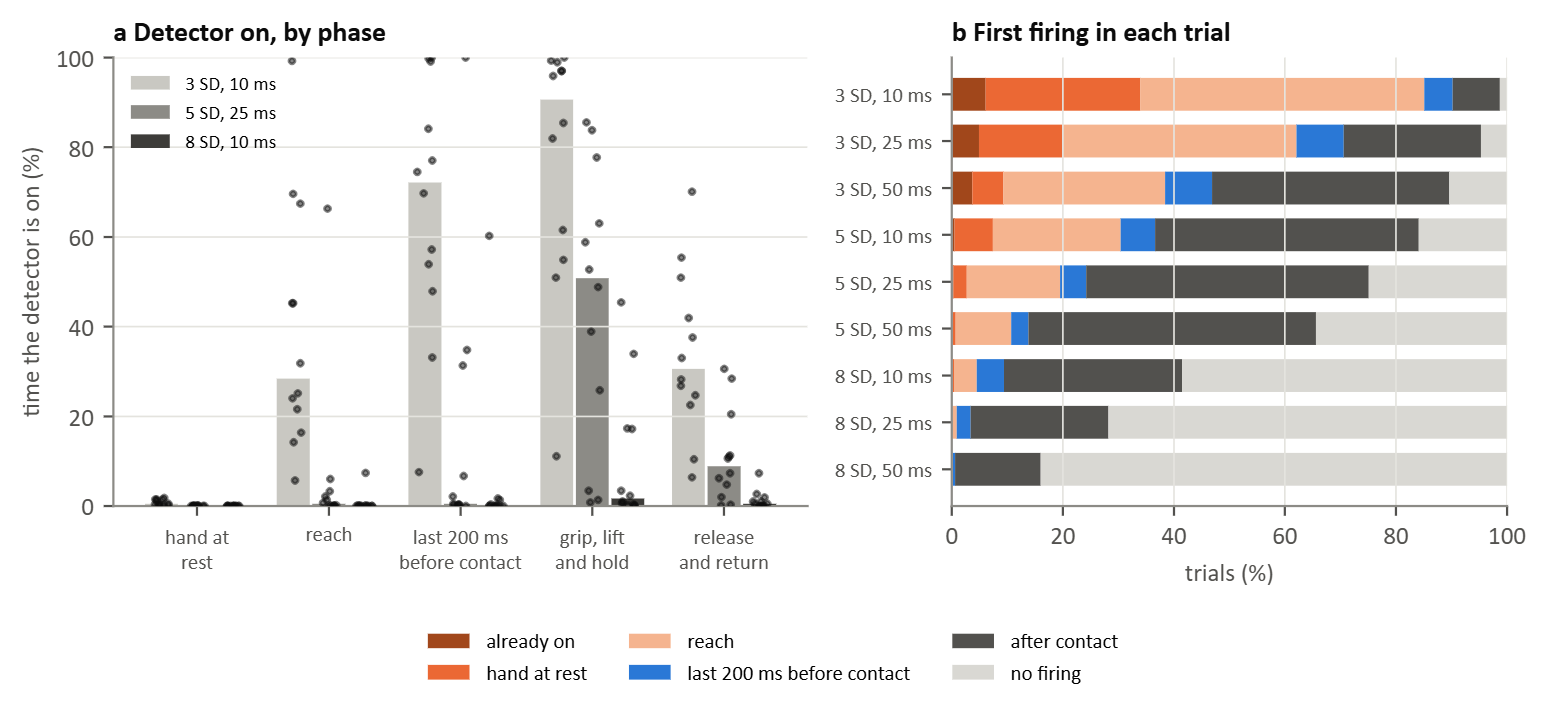

saved figures/figure14.png


In [9]:
SETTINGS = [f"k{k}_c{c}" for k in DET_K for c in DET_CONF_MS]
SHOW = ["k3_c10", "k5_c25", "k8_c10"]
LABEL = lambda key: f"{key.split('_')[0][1:]} SD, {key.split('_c')[1]} ms"
DETG = {}
print("setting | on (median): " + " / ".join(DET_PHASES) + " | false alarms per min at rest (median, range) | first firing vs contact (median of people, ms)")
for key in SETTINGS:
    V = [RES[p]["detection"][key] for p in OK]
    on = np.array([[v["on_fraction"][ph] for ph in DET_PHASES] for v in V])
    ff = np.array([[v["first_firing"][c] for c in FIRST_FIRE] for v in V], float)
    ff /= ff.sum(1, keepdims=True)
    fa = np.array([v["rest_false_alarms_per_min"] for v in V])
    fm = [v["first_firing_ms_median"] for v in V if v["first_firing_ms_median"] is not None]
    DETG[key] = dict(on_fraction_median={ph: round(float(np.median(on[:, i])), 3) for i, ph in enumerate(DET_PHASES)},
                     on_fraction_by_person={ph: [round(float(x), 3) for x in on[:, i]] for i, ph in enumerate(DET_PHASES)},
                     first_firing_mean_share={c: round(float(ff[:, i].mean()), 3) for i, c in enumerate(FIRST_FIRE)},
                     rest_false_alarms_per_min=dict(median=round(float(np.median(fa)), 2), range=[float(fa.min()), float(fa.max())]),
                     first_firing_vs_contact_ms_median=float(np.median(fm)) if fm else None, people_with_firings=len(fm))
    d = DETG[key]
    print(f"  {LABEL(key):11s} | " + " / ".join(f"{d['on_fraction_median'][ph]:.0%}" for ph in DET_PHASES)
          + f" | {d['rest_false_alarms_per_min']['median']:.2f} {d['rest_false_alarms_per_min']['range']} | {d['first_firing_vs_contact_ms_median']}")
print("\nfirst firing of each trial (mean share across people):")
for key in SETTINGS:
    print(f"  {LABEL(key):11s} " + " | ".join(f"{c} {DETG[key]['first_firing_mean_share'][c]:.0%}" for c in FIRST_FIRE))
MINUTES = {ph: round(float(sum(RES[p]["detection"]["k5_c25"]["minutes"][ph] for p in OK)), 1) for ph in DET_PHASES}
print("\nminutes tested in each phase (all people):", MINUTES)

fig, axs = plt.subplots(1, 2, figsize=(7.8, 3.1), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axs[0]
x = np.arange(len(DET_PHASES))
for i, (key, col) in enumerate(zip(SHOW, ("#c9c8c2", MUTED, "#3d3c39"))):
    xs = x + (i - 1) * 0.27
    ax.bar(xs, [100 * DETG[key]["on_fraction_median"][ph] for ph in DET_PHASES], 0.25, color=col, label=LABEL(key))
    for j, ph in enumerate(DET_PHASES):
        ax.scatter(xs[j] + rng_.uniform(-0.06, 0.06, len(OK)), 100 * np.array(DETG[key]["on_fraction_by_person"][ph]), s=5, color=INK, alpha=0.5, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(["hand at\nrest", "reach", "last 200 ms\nbefore contact", "grip, lift\nand hold", "release\nand return"], fontsize=7.5)
ax.set_ylabel("time the detector is on (%)"); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=7)
ax.set_title("a  Detector on, by phase")
ax = axs[1]
CAT_COL = {"already on": "#a1471b", "hand at rest": ORANGE, "reach": "#f5b48f", "last 200 ms before contact": BLUE,
           "after contact": INK2, "no firing": "#d9d8d3"}
for i, key in enumerate(SETTINGS):
    left = 0.0
    for c in FIRST_FIRE:
        w = 100 * DETG[key]["first_firing_mean_share"][c]
        ax.barh(len(SETTINGS) - 1 - i, w, left=left, color=CAT_COL[c], height=0.7, label=c if i == 0 else None)
        left += w
ax.set_yticks(range(len(SETTINGS))); ax.set_yticklabels([LABEL(k) for k in SETTINGS][::-1], fontsize=7.5)
ax.set_xlim(0, 100); ax.set_xlabel("trials (%)"); ax.grid(axis="y", visible=False)
ax.set_title("b  First firing in each trial")
h, l = ax.get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.0), fontsize=7.5)
fig.tight_layout()
save(fig, "figure14.png")

## Figure 15 · Grip force: delay of best prediction and forecast gain

**a.** R² of each person relative to their best delay (thin lines), median in black. **b.** Error reduction of the sEMG forecast against baseline 1 (the model's own current estimate) while grip force rises, holds steady or falls: median across people, band between the 25th and 75th percentiles. **c.** The same while grip force rises, split by the object's weight relative to the previous trial.

delay of best prediction: median 125 ms, IQR [88, 152] ms, range 60 to 300 ms; after 0 ms in 12 of 12
R2 at 0 ms: median 0.65; at the best delay: median 0.66

baseline 1: own estimate minus sEMG forecast (points of a typical grip): median (people with a clear gain / clear loss, Wilcoxon p)
  rising              30 ms  -0.4 (1/10, p=0.002)   50 ms  -0.5 (1/10, p=0.002)   70 ms  -0.5 (1/9, p=0.007)  100 ms  -0.2 (1/5, p=0.129)  150 ms  +0.4 (9/0, p=0.001)  200 ms  +0.9 (11/0, p=0.001)
  steady              30 ms  +0.1 (8/1, p=0.010)   50 ms  +0.1 (8/1, p=0.010)   70 ms  +0.1 (8/0, p=0.013)  100 ms  +0.2 (9/2, p=0.012)  150 ms  +0.2 (9/2, p=0.019)  200 ms  +0.3 (7/3, p=0.017)
  falling             30 ms  +0.1 (7/1, p=0.010)   50 ms  +0.3 (10/0, p=0.001)   70 ms  +0.5 (12/0, p=0.001)  100 ms  +0.8 (12/0, p=0.001)  150 ms  +0.9 (12/0, p=0.001)  200 ms  +1.0 (12/0, p=0.001)
  rising, same        30 ms  -0.4 (1/10, p=0.002)   50 ms  -0.5 (1/10, p=0.003)   70 ms  -0.5 (1/9, p=0.007)  100 ms  -

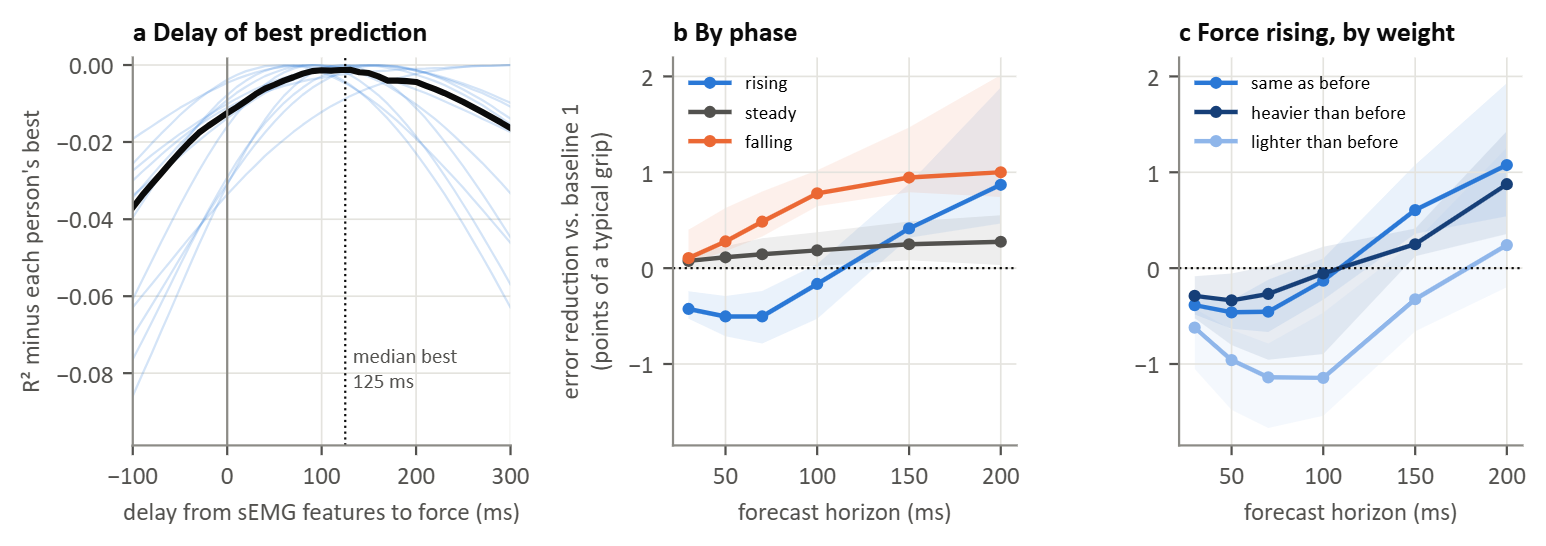

saved figures/figure15.png


In [10]:
DP = np.array([RES[p]["delay_profile_r2"] for p in OK])
BEST_D = np.array([DELAYS_MS[int(np.argmax(v))] for v in DP])
r0, rb = DP[:, DELAYS_MS.index(0)], DP.max(1)
print(f"delay of best prediction: median {np.median(BEST_D):.0f} ms, IQR [{np.percentile(BEST_D, 25):.0f}, {np.percentile(BEST_D, 75):.0f}] ms, "
      f"range {BEST_D.min()} to {BEST_D.max()} ms; after 0 ms in {int(np.sum(BEST_D > 0))} of {len(BEST_D)}")
print(f"R2 at 0 ms: median {np.median(r0):.2f}; at the best delay: median {np.median(rb):.2f}")
CASES = PHASES + [f"rising, {c}" for c in WEIGHT_CASES]
GROUP = {}
for b in MODELS[1:]:
    GROUP[b] = {}
    print(f"\n{b} minus sEMG forecast (points of a typical grip): median (people with a clear gain / clear loss, Wilcoxon p)")
    for c in CASES:
        G = np.array([RES[p]["gain_points"][b][c]["gain"] for p in OK])
        CI = np.array([RES[p]["gain_points"][b][c]["ci95"] for p in OK])
        rows = [dict(horizon_ms=hm, median=round(float(np.median(G[:, k])), 2), iqr=q(G[:, k]),
                     people_above_zero=int(np.sum(CI[:, k, 0] > 0)), people_below_zero=int(np.sum(CI[:, k, 1] < 0)),
                     wilcoxon_p=round(float(wilcoxon(G[:, k]).pvalue), 4)) for k, hm in enumerate(HORIZONS_MS)]
        GROUP[b][c] = rows
        print(f"  {c:17s}" + "".join(f"  {r['horizon_ms']:>3} ms {r['median']:+5.1f} ({r['people_above_zero']}/{r['people_below_zero']}, p={r['wilcoxon_p']:.3f})" for r in rows))
WEIGHT_DIFF = {}
print("\nweight change: gain in that case minus gain with the same weight (median across people, people lower, Wilcoxon p)")
Gs = np.array([RES[p]["gain_points"][MODELS[1]]["rising, same"]["gain"] for p in OK])
for c in WEIGHT_CASES[1:]:
    D = np.array([RES[p]["gain_points"][MODELS[1]][f"rising, {c}"]["gain"] for p in OK]) - Gs
    WEIGHT_DIFF[c] = [dict(horizon_ms=hm, median=round(float(np.median(D[:, k])), 2), people_lower=int(np.sum(D[:, k] < 0)),
                           wilcoxon_p=round(float(wilcoxon(D[:, k]).pvalue), 4)) for k, hm in enumerate(HORIZONS_MS)]
    print(f"  {c:8s}" + "".join(f"  {r['horizon_ms']:>3} ms {r['median']:+5.2f} ({r['people_lower']} lower, p={r['wilcoxon_p']:.3f})" for r in WEIGHT_DIFF[c]))
SAMPLES = {c: int(np.median([RES[p]["gain_points"][MODELS[1]][c]["samples"][HORIZONS_MS.index(100)] for p in OK])) for c in CASES}
print("\nsamples per person (median, at 100 ms):", SAMPLES)

fig, axs = plt.subplots(1, 3, figsize=(7.8, 2.8), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
axs[2].sharey(axs[1])
ax = axs[0]
for v in DP:
    ax.plot(DELAYS_MS, v - v.max(), color=BLUE, alpha=0.25, lw=0.8)
ax.plot(DELAYS_MS, np.median(DP - DP.max(1, keepdims=True), 0), color=INK, lw=2.2)
ax.axvline(np.median(BEST_D), color=INK, lw=0.8, ls=":"); ax.axvline(0, color=MUTED, lw=0.8)
lo = max(-0.2, min(-0.02, 1.15 * float((DP - DP.max(1, keepdims=True)).min())))
ax.text(np.median(BEST_D) + 8, 0.85 * lo, f"median best\n{np.median(BEST_D):.0f} ms", fontsize=7.5, color=INK2)
ax.set_xlim(min(DELAYS_MS), max(DELAYS_MS)); ax.set_ylim(lo, 0.002)
ax.set_xlabel("delay from sEMG features to force (ms)"); ax.set_ylabel("R² minus each person's best")
ax.set_title("a  Delay of best prediction")
for ax, cases, cols, title in ((axs[1], PHASES, (BLUE, INK2, ORANGE), "b  By phase"),
                               (axs[2], [f"rising, {c}" for c in WEIGHT_CASES], (BLUE, "#163f78", "#8fb6ea"), "c  Force rising, by weight")):
    for c, col in zip(cases, cols):
        G = np.array([RES[p]["gain_points"][MODELS[1]][c]["gain"] for p in OK])
        ax.fill_between(HORIZONS_MS, np.percentile(G, 25, 0), np.percentile(G, 75, 0), color=col, alpha=0.15, lw=0)
        lab = c if not c.startswith("rising, ") else c[8:] + (" as before" if c.endswith("same") else " than before")
        ax.plot(HORIZONS_MS, np.median(G, 0), color=col, marker="o", ms=3.5, label=lab)
    ax.axhline(0, color=INK, lw=0.8, ls=":")
    ax.set_xlabel("forecast horizon (ms)"); ax.set_xticks([50, 100, 150, 200]); ax.set_title(title)
    ax.legend(loc="upper left", fontsize=7)
axs[1].set_ylabel("error reduction vs. baseline 1\n(points of a typical grip)")
fig.tight_layout()
save(fig, "figure15.png")

## Save the numbers

In [11]:
PERSON = {}
for p in OK:
    r = RES[p]
    PERSON[str(p)] = dict(trials=r["trials"], onset_vs_contact_ms=r["onset_vs_contact_ms"], onset_vs_hand_start_ms=r["onset_vs_hand_start_ms"],
                          onset_found=r["onset_found"], detection_5sd_25ms=r["detection"]["k5_c25"],
                          best_delay_ms=DELAYS_MS[int(np.argmax(r["delay_profile_r2"]))], r2_best_delay=max(r["delay_profile_r2"]),
                          r2_zero_delay=r["delay_profile_r2"][DELAYS_MS.index(0)],
                          gain_vs_baseline1={c: r["gain_points"][MODELS[1]][c]["gain"] for c in CASES})
OUT = dict(participants=OK, trials=int(sum(RES[p]["trials"] for p in OK)), onsets=ONSETS, events_vs_contact=EVENTS, burst_after_contact=BURST,
           detector=DETG, detector_minutes=MINUTES,
           delay_of_best_prediction=dict(delays_ms=DELAYS_MS, median_ms=float(np.median(BEST_D)),
                                         iqr_ms=[float(np.percentile(BEST_D, 25)), float(np.percentile(BEST_D, 75))],
                                         r2_at_0_median=float(np.median(r0)), r2_at_best_median=float(np.median(rb))),
           forecast_gain_group=GROUP, weight_case_minus_same=WEIGHT_DIFF, samples_per_person_median=SAMPLES, per_participant=PERSON,
           settings=dict(horizons_ms=HORIZONS_MS, detector_k_sd=list(DET_K), detector_confirmation_ms=list(DET_CONF_MS),
                         detector_muscles=[MUSCLES[k] for k in HAND], onset=dict(k_sd=ONSET_K, ms=ONSET_MS),
                         bootstrap=N_BOOT, block_s=BLOCK / FS_F))
txt = json.dumps(OUT, indent=1)
txt = re.sub(r"\[\s+([^\[\]{}]*?)\s+\]", lambda m: "[" + re.sub(r"\s+", " ", m.group(1)) + "]", txt)
(RES_DIR / "way_eeg_gal.json").write_text(txt + "\n")
print("saved results/way_eeg_gal.json")

saved results/way_eeg_gal.json
